# 09. T1 jako kontrola negatywna: cisza kontra sala konferencyjna

Zadanie B9 (strumień „B. Dane i dowody”, SHOULD, zawęża issue #21).

**Pytanie:** ile w naszych wskaźnikach zmienia **otoczenie** (sala hackathonu w południe kontra cichy pokój wieczorem),
a ile **stan człowieka**? I co z tego wynika dla fałszywych alarmów i prób reakcji, które produkt wywołuje?

**Dane:**

- **T1** (`wojtek-t1`, wieczór, słuchawki z ANC i biały szum): 60 s oczy otwarte z fiksacją wzroku (kalibracja), 60 s oczy zamknięte,
  60 s liczenie, potem **15 min monotonii** z otwartymi oczami. KSS 5, senności nie było (`docs/sesja-monotonii-wojtek.md`).
  To 15 minut prawdziwie negatywnego materiału: ani senności, ani zamkniętych oczu, bardzo czysty sygnał.
- **Południe** (adi, filip, rudy, wojtek, hala hackathonu): bloki `neutral` (swobodna rozmowa), `reading`, `math`.
  Bloki `eyes_closed` i `control` (mruganie, szczęka, ruch głowy) pokazujemy osobno, bo nie są warunkiem „otwarte oczy, spokój”.

**Ważne zastrzeżenia od początku:** T1 to jedna osoba i jedna sesja. Bloki z południa są krótkie (czytanie i liczenie po 0,5–1,6 min).
Kalibracja produktu to zawsze pierwsza minuta czystych okien tego samego nagrania: w T1 fiksacja wzroku w ciszy, w południe rozmowa.
Warunki różnią się więc naraz otoczeniem, czynnością, porą dnia i założeniem czepka. Notebook pokazuje, jak duże są te różnice,
a nie rozdziela ich przyczynowo.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.signal import welch
from scipy.stats import chi2, theilslopes

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

FS = 250
RNG = np.random.default_rng(9)
N_BOOT = 2000
BOOT_BLOCK = 30          # moving-block bootstrap: 30 consecutive windows (30 s), windows overlap and are autocorrelated


def find_recordings():
    """Locate data/recordings (repo checkout, Colab upload, or fresh clone)."""
    for p in [Path("../recordings"), Path("data/recordings"), Path("recordings"), Path("/content/repo/data/recordings")]:
        if list(p.glob("*raw.fif")):
            return p
    import subprocess
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/wskalecki/Heroes_of_the_brain_AI_All_IN.git", "/content/repo"],
        capture_output=True,
    )
    p = Path("/content/repo/data/recordings")
    if list(p.glob("*raw.fif")):
        return p
    raise FileNotFoundError(
        "Nie znaleziono plików *raw.fif. Sklonuj repo (jeśli jest prywatne, trzeba tokenu) "
        "i uruchom notebook z folderu data/analysis."
    )


REC = find_recordings()
REPO = REC.resolve().parent.parent
SRC = REPO / "src"
if not (SRC / "wachta" / "pipeline.py").exists():
    raise ImportError(
        "Nie znaleziono pakietu wachta (src/wachta). Ten notebook liczy wskaźnik kodem produktu, "
        "więc potrzebuje całego repo, a nie samych nagrań."
    )
sys.path.insert(0, str(SRC))

from wachta.config import CHANNELS, Config          # noqa: E402
from wachta.index import VigilanceIndex             # noqa: E402
from wachta.pipeline import Pipeline                # noqa: E402
from wachta.recordings import find_recordings as wachta_recordings, load_annotations  # noqa: E402

CFG = Config()
print("Nagrania:", ", ".join(wachta_recordings(REC)))
print(f"Konfiguracja produktu: okna {CFG.win_s:.0f} s co {CFG.step_s:.0f} s, odrzucenie > {CFG.reject_uv:.0f} µV, "
      f"kalibracja {CFG.cal_windows} czystych okien, alarm z > {CFG.z_enter} przez {CFG.lapse_min_s:.0f} s, "
      f"próba z > {CFG.probe_z} przez {CFG.probe_min_s:.0f} s, przerwa między próbami {CFG.probe_cooldown_s:.0f} s")

Nagrania: adi, filip, rudy, wojtek-t1, wojtek
Konfiguracja produktu: okna 2 s co 1 s, odrzucenie > 300 µV, kalibracja 60 czystych okien, alarm z > 2.5 przez 3 s, próba z > 1.5 przez 2 s, przerwa między próbami 45 s


## Metoda

Każde nagranie przechodzi przez **kod produktu** (`src/wachta`, bez zmian): filtr przyczynowy 1–40 Hz z notchem 50 Hz,
okna 2 s co 1 s, odrzucenie okna przy amplitudzie szczyt-szczyt > 300 µV, kalibracja z pierwszych 60 czystych okien
(mediana i MAD), wskaźnik szybki = mediana z-score'u wyrazistości alfy na O1/O2 z ostatnich 5 okien, alarm (spadek czujności)
przy wskaźniku > 2,5 przez ≥ 3 s, próba reakcji przy wskaźniku ≥ 1,5 przez 2 s (przerwa między próbami 45 s), mrugnięcia na F3/F4.

Na tych samych 2-sekundowych oknach liczymy miary jakości sygnału, niezależne od produktu:

| Miara | Definicja |
|---|---|
| okna odrzucone | odsetek okien z flagą `bad` produktu (> 300 µV) |
| brum sieci 50 Hz | moc 49–51 Hz względem 20–30 Hz w dB, średnie widmo 8 kanałów, sygnał tylko z filtrem górnoprzepustowym 1 Hz |
| EMG | średnia gęstość mocy 60–95 Hz (µV²/Hz), te same dane z filtrem 1 Hz; w tabeli mediana okien bloku |
| ruch | wygładzona (1 s) zmiana sygnału akcelerometru, jak w notebookach 01 i 03; w tabeli mediana bloku względem mediany T1 monotonii |
| z p50/p90/p99, z>1,5, z>2,5 | rozkład wskaźnika szybkiego w czystych oknach po kalibracji |
| alarmy/h, próby/h | zdarzenia produktu w bloku na godzinę czasu po kalibracji, 95% CI z rozkładu Poissona |
| mrugnięcia/min | detektor produktu (`blinks.py`) |
| tętno | tylko T1, wartości z `docs/sesja-monotonii-wojtek.md` (pasek HRM; to jedyne źródło, plik zegarka nie jest w repo) |

Okno należy do bloku, gdy mieści się w nim w całości. Okna nakładają się i są zależne, więc niepewność różnic liczymy
**bootstrapem blokowym** (bloki po 30 kolejnych okien), a niepewność częstości zdarzeń z rozkładu Poissona.

In [2]:
def run_product(eeg_volts):
    """Same loop as wachta.pipeline.run_offline, but keeps the pipeline object (for blink times)."""
    pipe = Pipeline(CFG)
    out = []
    for start in range(0, eeg_volts.shape[1], CFG.step_samples):
        out.extend(pipe.push(eeg_volts[:, start:start + CFG.step_samples]))
    return out, np.array(pipe.blinks.blinks)


def accel_jerk(raw):
    """Smoothed magnitude of accelerometer change (movement proxy, as in notebooks 01/03), one value per sample."""
    a = raw.copy().pick(["Accel_x", "Accel_y", "Accel_z"]).get_data()
    j = np.sqrt((np.diff(a, axis=1) ** 2).sum(0))
    j = np.r_[j[0], j]
    return pd.Series(j).rolling(FS, center=True, min_periods=1).mean().values


def window_table(path):
    """One row per product window (2 s, 1 s step): product outputs plus quality metrics on the same samples."""
    raw = mne.io.read_raw_fif(path, preload=True)
    eeg = raw.get_data(picks=list(CHANNELS))
    results, blinks = run_product(eeg)
    hp = raw.copy().pick(list(CHANNELS)).filter(1, None).get_data() * 1e6     # 1 Hz high-pass only, µV
    jerk = accel_jerk(raw)
    n_win = CFG.win_samples
    rows = []
    for r in results:
        end = int(round(r["t"] * FS))
        start = end - n_win
        f, p = welch(hp[:, start:end], FS, nperseg=n_win, axis=-1)
        p = p.mean(0)                                                          # mean PSD over 8 channels
        rows.append({
            "t": r["t"], "bad": r["bad"], "calibrated": r["calibrated"],
            "fast": np.nan if r["fast"] is None else r["fast"],               # product fast index (median of 5 z)
            "z": np.nan if r["z"] is None else r["z"]["alpha_prom"],          # per-window z of alpha prominence
            "z_tab": np.nan if r["z"] is None else r["z"]["tab_ratio"],
            "alpha_prom": r["features"]["alpha_prom"], "tab_ratio": r["features"]["tab_ratio"],
            "new_lapse": r["new_lapse"], "lapse": r["lapse"], "probe": r["probe"],
            "mains_db": 10 * np.log10(p[(f >= 49) & (f <= 51)].mean() / p[(f >= 20) & (f <= 30)].mean()),
            "emg": p[(f >= 60) & (f <= 95)].mean(),                            # µV²/Hz
            "jerk": jerk[start:end].mean(),
        })
    return pd.DataFrame(rows), blinks, load_annotations(path)


RECS = wachta_recordings(REC)
DATA = {name: window_table(path) for name, path in RECS.items()}
{name: f"{len(t)} okien, {len(b)} mrugnięć" for name, (t, b, _) in DATA.items()}

{'adi': '546 okien, 49 mrugnięć',
 'filip': '878 okien, 175 mrugnięć',
 'rudy': '541 okien, 121 mrugnięć',
 'wojtek-t1': '1089 okien, 84 mrugnięć',
 'wojtek': '507 okien, 86 mrugnięć'}

## 1. Tabela warunków

Wszystkie wiersze liczone tak samo. W T1 blok „oczy otwarte” to kalibracja, więc nie ma w nim z-score'u ani zdarzeń.
Częstości liczymy tylko dla bloków z co najmniej 20 s po kalibracji. W blokach rozmowy z południa pierwsza minuta to kalibracja,
więc „min po kal.” jest krótsze niż blok.

In [3]:
HR_T1 = {"eyes_open": 93, "eyes_closed": 90, "math": 93, "monotony": 97}   # bpm, docs/sesja-monotonii-wojtek.md (only source)
NAMES = {"neutral": "rozmowa", "eyes_open": "oczy otwarte (kalibracja)", "eyes_closed": "oczy zamknięte",
         "reading": "czytanie", "math": "liczenie", "monotony": "monotonia", "control": "kontrolny"}
OPEN_EYES = ("neutral", "reading", "math", "eyes_open", "monotony")
REF_JERK = None


def poisson_ci(k, hours):
    lo = chi2.ppf(0.025, 2 * k) / 2 if k > 0 else 0.0
    hi = chi2.ppf(0.975, 2 * k + 2) / 2
    return lo / hours, hi / hours


def block_windows(name, label):
    t, blinks, blocks = DATA[name]
    b = next(b for b in blocks if b.label == label)
    m = (t.t >= b.onset + CFG.win_s) & (t.t <= b.end)      # windows fully inside the block
    return t[m], blinks[(blinks >= b.onset) & (blinks <= b.end)], b


def summary(name, label):
    w, bl, b = block_windows(name, label)
    cal = w[w.calibrated]
    clean = cal[~cal.bad]
    hours = len(cal) * CFG.step_s / 3600
    fast = clean.fast.dropna()
    row = {
        "sesja": "T1 wieczór (cicho)" if name.endswith("-t1") else "południe (sala)",
        "osoba": name.replace("-t1", ""), "blok": NAMES[label], "label": label, "rec": name,
        "min": round(len(w) / 60, 1),
        "odrzucone %": 100 * w.bad.mean(),
        "sieć 50 Hz [dB]": w.mains_db.median(),
        "EMG 60–95 Hz [µV²/Hz]": w.emg.median(),
        "ruch [× T1 monot.]": w.jerk.median(),
        "z p50": np.percentile(fast, 50) if len(fast) else np.nan,
        "z p90": np.percentile(fast, 90) if len(fast) else np.nan,
        "z p99": np.percentile(fast, 99) if len(fast) else np.nan,
        "z>1,5 %": 100 * (fast > CFG.probe_z).mean() if len(fast) else np.nan,
        "z>2,5 %": 100 * (fast > CFG.z_enter).mean() if len(fast) else np.nan,
        "alarmy": int(cal.new_lapse.sum()),
        "próby": int(cal.probe.sum()),
        "min po kal.": round(hours * 60, 1),
        "mrugnięcia/min": len(bl) / (b.duration / 60),
        "tętno [bpm]": HR_T1.get(label) if name.endswith("-t1") else np.nan,
    }
    if len(cal) >= 20:                                     # rates only with at least 20 s after calibration
        row["alarmy/h"] = row["alarmy"] / hours
        row["próby/h"] = row["próby"] / hours
        row["próby/h CI"] = "{:.0f}–{:.0f}".format(*poisson_ci(row["próby"], hours))
        row["alarmy/h CI"] = "{:.0f}–{:.0f}".format(*poisson_ci(row["alarmy"], hours))
    return row


ORDER = [("wojtek-t1", "eyes_open"), ("wojtek-t1", "monotony"), ("wojtek-t1", "eyes_closed"), ("wojtek-t1", "math")]
NOON = [n for n in RECS if not n.endswith("-t1")]
ORDER += [(n, lab) for n in NOON for lab in ("neutral", "reading", "math")]
EXTRA = [(n, lab) for n in NOON for lab in ("eyes_closed", "control")]

TAB = pd.DataFrame([summary(n, lab) for n, lab in ORDER])
EXTRA_TAB = pd.DataFrame([summary(n, lab) for n, lab in EXTRA])
REF_JERK = TAB.set_index(["rec", "label"]).loc[("wojtek-t1", "monotony"), "ruch [× T1 monot.]"]
for tab in (TAB, EXTRA_TAB):
    tab["ruch [× T1 monot.]"] /= REF_JERK

COLS = ["sesja", "osoba", "blok", "min", "odrzucone %", "sieć 50 Hz [dB]", "EMG 60–95 Hz [µV²/Hz]", "ruch [× T1 monot.]",
        "z p50", "z p90", "z p99", "z>1,5 %", "z>2,5 %", "min po kal.", "alarmy", "alarmy/h", "próby", "próby/h",
        "próby/h CI", "mrugnięcia/min", "tętno [bpm]"]
FMT = {"min": "{:.1f}", "odrzucone %": "{:.1f}", "sieć 50 Hz [dB]": "{:.1f}", "EMG 60–95 Hz [µV²/Hz]": "{:.3f}",
       "ruch [× T1 monot.]": "{:.1f}", "z p50": "{:.2f}", "z p90": "{:.2f}", "z p99": "{:.2f}", "z>1,5 %": "{:.1f}",
       "z>2,5 %": "{:.1f}", "min po kal.": "{:.1f}", "alarmy/h": "{:.0f}", "próby/h": "{:.0f}", "mrugnięcia/min": "{:.1f}",
       "tętno [bpm]": "{:.0f}"}
print("Tabela 1. Bloki z otwartymi oczami (i bloki T1). Z-score: wskaźnik szybki produktu (mediana z 5 okien), tylko czyste okna po kalibracji.")
display(TAB[COLS].style.format(FMT, na_rep="–").hide(axis="index"))

Tabela 1. Bloki z otwartymi oczami (i bloki T1). Z-score: wskaźnik szybki produktu (mediana z 5 okien), tylko czyste okna po kalibracji.


sesja,osoba,blok,min,odrzucone %,sieć 50 Hz [dB],EMG 60–95 Hz [µV²/Hz],ruch [× T1 monot.],z p50,z p90,z p99,"z>1,5 %","z>2,5 %",min po kal.,alarmy,alarmy/h,próby,próby/h,próby/h CI,mrugnięcia/min,tętno [bpm]
T1 wieczór (cicho),wojtek,oczy otwarte (kalibracja),1.0,0.0,-4.5,0.010,1.0,–,–,–,–,–,0.0,0,–,0,–,–,4.0,93
T1 wieczór (cicho),wojtek,monotonia,15.0,0.9,-4.8,0.009,1.0,0.54,1.54,2.34,11.2,0.3,15.0,0,0,11,44,22–79,5.1,97
T1 wieczór (cicho),wojtek,oczy zamknięte,1.0,0.0,-7.5,0.006,0.6,2.31,3.20,3.38,79.7,42.4,1.0,2,122,1,61,2–340,1.0,90
T1 wieczór (cicho),wojtek,liczenie,1.0,0.0,-6.2,0.007,0.7,0.93,1.57,1.95,11.9,0.0,1.0,0,0,1,61,2–340,1.0,93
południe (sala),adi,rozmowa,5.0,7.7,30.2,0.069,1.7,-0.28,0.65,1.30,0.0,0.0,3.9,0,0,0,0,0–57,3.4,–
południe (sala),adi,czytanie,1.2,12.2,29.8,0.071,1.3,-0.19,0.93,1.44,0.0,0.0,1.2,0,0,0,0,0–179,7.2,–
południe (sala),adi,liczenie,1.1,11.6,34.5,0.011,0.8,0.14,0.70,0.95,0.0,0.0,1.1,0,0,0,0,0–192,9.4,–
południe (sala),filip,rozmowa,10.0,3.0,13.9,0.016,1.2,-0.08,0.92,2.22,3.3,0.6,9.0,1,7,4,27,7–68,14.6,–
południe (sala),filip,czytanie,1.3,0.0,14.8,0.006,0.8,-0.29,1.46,3.73,7.6,2.5,1.3,0,0,0,0,0–168,3.0,–
południe (sala),filip,liczenie,1.6,0.0,13.4,0.006,0.7,-0.59,0.20,1.03,0.0,0.0,1.6,0,0,0,0,0–134,0.0,–


In [4]:
print("Tabela 1b. Dla porządku: bloki z południa, których nie porównujemy (oczy zamknięte i blok kontrolny: mruganie, szczęka, ruch głowy).")
display(EXTRA_TAB[COLS].style.format(FMT, na_rep="–").hide(axis="index"))

Tabela 1b. Dla porządku: bloki z południa, których nie porównujemy (oczy zamknięte i blok kontrolny: mruganie, szczęka, ruch głowy).


sesja,osoba,blok,min,odrzucone %,sieć 50 Hz [dB],EMG 60–95 Hz [µV²/Hz],ruch [× T1 monot.],z p50,z p90,z p99,"z>1,5 %","z>2,5 %",min po kal.,alarmy,alarmy/h,próby,próby/h,próby/h CI,mrugnięcia/min,tętno [bpm]
południe (sala),adi,oczy zamknięte,1.0,0.0,29.8,0.056,0.6,2.15,3.11,4.07,67.8,35.6,1.0,2,122,1,61,2–340,0.0,–
południe (sala),adi,kontrolny,0.7,35.7,26.9,0.230,3.3,-0.40,0.45,0.66,0.0,0.0,0.7,0,0,0,0,0–316,16.7,–
południe (sala),filip,oczy zamknięte,1.0,0.0,12.2,0.036,0.8,4.32,5.15,5.30,93.2,93.2,1.0,1,61,1,61,2–340,1.0,–
południe (sala),filip,kontrolny,0.7,25.6,6.1,0.399,3.3,-0.85,0.04,0.14,0.0,0.0,0.7,0,0,0,0,0–341,35.4,–
południe (sala),rudy,oczy zamknięte,1.0,0.0,11.8,0.026,0.4,2.72,3.08,3.69,91.5,57.6,1.0,1,61,1,61,2–340,0.0,–
południe (sala),rudy,kontrolny,0.3,77.8,4.5,0.301,2.4,-0.06,-0.04,-0.04,0.0,0.0,0.3,0,–,0,–,–,67.0,–
południe (sala),wojtek,oczy zamknięte,1.0,11.3,1.1,0.096,2.6,2.66,4.36,5.05,73.6,52.8,1.0,2,116,1,58,1–324,9.5,–
południe (sala),wojtek,kontrolny,0.4,75.0,3.6,0.337,2.5,2.68,2.79,2.79,100.0,75.0,0.4,0,0,1,150,4–836,51.8,–


In [5]:
def pooled(rows):
    """Rates pooled over several blocks: events over the summed calibrated time, with an exact Poisson CI."""
    hours = rows["min po kal."].sum() / 60
    out = {"bloków": len(rows), "min po kal.": round(hours * 60, 1)}
    for ev in ("alarmy", "próby"):
        k = int(rows[ev].sum())
        lo, hi = poisson_ci(k, hours)
        out[ev] = k
        out[ev + "/h"] = f"{k / hours:.0f} ({lo:.0f}–{hi:.0f})"
    return out


is_t1 = TAB.rec == "wojtek-t1"
POOL = pd.DataFrame({
    "T1 monotonia (cicho, 15 min)": pooled(TAB[is_t1 & (TAB.label == "monotony")]),
    "południe: wszystkie bloki z otwartymi oczami, 4 osoby": pooled(TAB[~is_t1]),
    "południe: sama rozmowa, 4 osoby": pooled(TAB[~is_t1 & (TAB.label == "neutral")]),
    "południe: czytanie i liczenie, 4 osoby": pooled(TAB[~is_t1 & TAB.label.isin(["reading", "math"])]),
    "południe: wojtek, 3 bloki": pooled(TAB[TAB.rec == "wojtek"]),
}).T
print("Tabela 2. Alarmy i próby reakcji na godzinę, zsumowane po blokach (95% CI Poissona).")
POOL

Tabela 2. Alarmy i próby reakcji na godzinę, zsumowane po blokach (95% CI Poissona).


,bloków,min po kal.,alarmy,alarmy/h,próby,próby/h
"T1 monotonia (cicho, 15 min)",1,15.0,0,0 (0–15),11,44 (22–79)
"południe: wszystkie bloki z otwartymi oczami, 4 osoby",12,29.5,1,2 (0–11),9,18 (8–35)
"południe: sama rozmowa, 4 osoby",4,20.7,1,3 (0–16),8,23 (10–46)
"południe: czytanie i liczenie, 4 osoby",8,8.8,0,0 (0–25),1,7 (0–38)
"południe: wojtek, 3 bloki",3,5.9,0,0 (0–38),4,41 (11–104)


**Co pokazuje tabela:**

- **Jakość sygnału zależy od otoczenia i sesji bardzo mocno.** W T1 monotonii odrzucono 0,9% okien, a brum sieci jest *poniżej*
  tła 20–30 Hz (−4,8 dB). W południe bloki z otwartymi oczami mają 0–21,9% odrzuconych okien (rozmowa 3,0–15,1%), a brum
  zależy od sesji: adi 29,8–34,5 dB, filip 13,4–14,8 dB, rudy 5,2–12,5 dB, wojtek 1,1–3,9 dB.
- **EMG zależy bardziej od czynności niż od sali.** T1 monotonia: 0,009 µV²/Hz. Rozmowa w południe: 0,016–0,069 µV²/Hz
  (mówienie napina mięśnie). Ale czytanie i liczenie Filipa w tej samej sali (0,006) jest równie czyste jak T1, a liczenie Rudego (0,161) najgorsze.
- **Ruch:** rozmowa 0,9–2,2 razy więcej niż T1 monotonia, czytanie i liczenie 0,6–1,8 razy.
- **Rozkład wskaźnika w T1 monotonii jest przesunięty w górę:** mediana 0,54, p90 1,54, p99 2,34; 11,2% czystych okien powyżej 1,5,
  0,3% powyżej 2,5. W rozmowie z południa mediana od −0,28 do 0,19, p90 od 0,65 do 1,56, powyżej 1,5 od 0 do 10,6% okien.
  Hałaśliwa sala **nie** podnosi wskaźnika, raczej przeciwnie.
- **Fałszywe alarmy:** T1 monotonia 0 w 15 min; wszystkie bloki z otwartymi oczami z południa razem 1 w 29,5 min
  (2 na godzinę, 95% CI 0–11), ten jeden u Filipa w rozmowie.
- **Próby reakcji:** T1 monotonia 11 w 15 min, czyli 44 na godzinę (22–79). Południe razem: 9 w 29,5 min, 18 na godzinę (8–35);
  sama rozmowa 23 na godzinę (10–46); Wojtek w południe 4 w 5,9 min, 41 na godzinę (11–104). Częstość prób w ciszy jest więc
  co najmniej taka jak w sali, nie mniejsza.
- Mrugnięcia: T1 monotonia 5,1 na minutę, rozmowa w południe 3,4–14,6. Tętno w T1: 93 / 90 / 93 / 97 bpm (oczy otwarte / zamknięte / liczenie / monotonia).

Przy krótkich blokach (ok. 1 min) jedno zdarzenie to 60 na godzinę, a przedział ufności sięga kilkuset, więc pojedynczych wierszy
czytania i liczenia nie należy porównywać; dlatego tabela 2 sumuje bloki.

## 2. Gdzie otoczenie waży najwięcej: różnice względem T1 monotonii

Ta sama osoba (Wojtek) w sali kontra w ciszy, oraz pozostałe trzy osoby w sali. Różnica = warunek z południa minus T1 monotonia.
Dla EMG i ruchu podajemy krotność median. Bootstrap blokowy losuje fragmenty po 30 s osobno w każdym bloku.

In [6]:
def block_boot_idx(n):
    """Indices of one moving-block bootstrap resample of n consecutive windows."""
    if n <= BOOT_BLOCK:
        return RNG.integers(0, n, n)
    starts = RNG.integers(0, n - BOOT_BLOCK + 1, int(np.ceil(n / BOOT_BLOCK)))
    return np.concatenate([np.arange(s, s + BOOT_BLOCK) for s in starts])[:n]


def stats_of(w):
    clean = w[w.calibrated & ~w.bad]
    return np.array([
        100 * w.bad.mean(),                       # rejected %
        np.median(w.mains_db),                    # mains dB
        np.log10(np.median(w.emg)),               # log10 EMG
        np.log10(np.median(w.jerk)),              # log10 movement
        np.nanmedian(clean.fast) if clean.fast.notna().any() else np.nan,
        100 * np.nanmean(clean.fast.dropna() > CFG.probe_z) if clean.fast.notna().any() else np.nan,
    ])


def boot(groups):
    """Point estimate and bootstrap draws of stats for a list of window tables (blocks resampled separately, then pooled)."""
    point = stats_of(pd.concat(groups))
    draws = []
    for _ in range(N_BOOT):
        draws.append(stats_of(pd.concat([g.iloc[block_boot_idx(len(g))] for g in groups])))
    return point, np.array(draws)


REF = [block_windows("wojtek-t1", "monotony")[0]]
COMPARE = {
    "wojtek, rozmowa": [block_windows("wojtek", "neutral")[0]],
    "wojtek, czytanie + liczenie": [block_windows("wojtek", lab)[0] for lab in ("reading", "math")],
    "inni (adi, filip, rudy), rozmowa": [block_windows(n, "neutral")[0] for n in NOON if n != "wojtek"],
    "inni, czytanie + liczenie": [block_windows(n, lab)[0] for n in NOON if n != "wojtek" for lab in ("reading", "math")],
}
ref_point, ref_draws = boot(REF)
eff_rows = []
for label, groups in COMPARE.items():
    point, draws = boot(groups)
    d, dd = point - ref_point, draws - ref_draws
    lo, hi = np.nanpercentile(dd, 2.5, axis=0), np.nanpercentile(dd, 97.5, axis=0)

    def fmt(i, scale=lambda x: x, f="{:.1f}"):
        return (f + " [" + f + "; " + f + "]").format(scale(d[i]), scale(lo[i]), scale(hi[i]))

    ratio = lambda x: 10 ** x
    eff_rows.append({
        "porównanie z T1 monotonią": label,
        "odrzucone: różnica [pp]": fmt(0),
        "sieć 50 Hz: różnica [dB]": fmt(1),
        "EMG: krotność": fmt(2, ratio),
        "ruch: krotność": fmt(3, ratio),
        "mediana z: różnica": fmt(4, f="{:.2f}"),
        "okna z>1,5: różnica [pp]": fmt(5),
    })
print(f"T1 monotonia (punkt odniesienia): odrzucone {ref_point[0]:.1f}%, sieć {ref_point[1]:.1f} dB, "
      f"EMG {10 ** ref_point[2]:.4f} µV²/Hz, mediana z {ref_point[4]:.2f}, z>1,5 w {ref_point[5]:.1f}% okien")
print("Tabela 3. Różnica (warunek z południa minus T1 monotonia) i 95% CI z bootstrapu blokowego (bloki po 30 okien).")
EFF = pd.DataFrame(eff_rows).set_index("porównanie z T1 monotonią")
EFF

T1 monotonia (punkt odniesienia): odrzucone 0.9%, sieć -4.8 dB, EMG 0.0095 µV²/Hz, mediana z 0.54, z>1,5 w 11.2% okien
Tabela 3. Różnica (warunek z południa minus T1 monotonia) i 95% CI z bootstrapu blokowego (bloki po 30 okien).


,odrzucone: różnica [pp],sieć 50 Hz: różnica [dB],EMG: krotność,ruch: krotność,mediana z: różnica,"okna z>1,5: różnica [pp]"
porównanie z T1 monotonią,,,,,,
"wojtek, rozmowa",8.8 [3.9; 16.3],6.4 [6.0; 6.9],5.9 [2.6; 10.7],2.2 [1.0; 3.1],-0.35 [-0.59; 0.08],-0.7 [-8.6; 10.5]
"wojtek, czytanie + liczenie",-0.9 [-1.8; -0.2],7.0 [6.7; 7.4],3.6 [2.7; 4.0],0.9 [0.5; 1.0],-0.10 [-0.43; -0.00],-5.0 [-14.8; -2.9]
"inni (adi, filip, rudy), rozmowa",6.3 [3.5; 9.1],19.1 [18.5; 19.9],3.2 [2.2; 4.4],1.2 [0.8; 1.7],-0.69 [-0.91; -0.42],-9.0 [-13.6; -4.5]
"inni, czytanie + liczenie",7.4 [2.9; 11.4],19.2 [18.8; 19.5],1.5 [1.1; 1.7],0.8 [0.6; 1.0],-0.63 [-0.85; -0.43],-9.6 [-14.4; -5.6]


**Wynik:**

- **Najpewniejszy efekt otoczenia to brum sieci:** +6,4 dB [6,0; 6,9] u Wojtka w rozmowie, +19,1 dB [18,5; 19,9] u pozostałych.
  Drugi to **EMG**: 5,9 razy [2,6; 10,7] więcej u Wojtka w rozmowie, 3,6 razy [2,7; 4,0] przy jego czytaniu i liczeniu,
  1,5 razy [1,1; 1,7] przy czytaniu i liczeniu pozostałych.
- **Odrzucone okna:** w rozmowie o 8,8 pp [3,9; 16,3] (Wojtek) i 6,3 pp [3,5; 9,1] (pozostali) więcej niż w T1;
  przy czytaniu i liczeniu pozostałych o 7,4 pp [2,9; 11,4]. Krótkie bloki czytania i liczenia Wojtka nie miały odrzuceń (−0,9 pp).
- **Ruch** różni się wyraźnie tylko w rozmowie Wojtka (2,2 razy [1,0; 3,1]); przy czytaniu i liczeniu jest podobny lub mniejszy niż w T1.
- **Wskaźnik czujności idzie w drugą stronę:** w sali mediana z jest *niższa* niż w T1 monotonii (pozostali: −0,69 [−0,91; −0,42]
  w rozmowie, −0,63 [−0,85; −0,43] przy czytaniu i liczeniu; Wojtek w rozmowie −0,35 [−0,59; 0,08]), a okien powyżej progu próby
  jest mniej lub tyle samo. Szum sali nie przenosi się na wskaźnik: okna z artefaktami produkt odrzuca, notch tłumi 50 Hz,
  a wyrazistość alfy to stosunek mocy 8–12 Hz do sąsiednich pasm (5–7 i 14–16 Hz), na który szerokopasmowe EMG działa słabo.

Bootstrap blokowy przy blokach 1-minutowych (2 fragmenty po 30 s) zaniża niepewność; przedziały dla „czytanie + liczenie” traktujemy jako orientacyjne.

## 2b. Co przesuwa wskaźnik bardziej niż sala: kalibracja z innej sesji

Wojtek ma dwie sesje, więc możemy sprawdzić, co się stanie, gdy z-score liczymy względem kalibracji **z drugiej sesji**
(inna sala, pora dnia, czynność i założenie czepka). Z-score'y idą do świeżego `VigilanceIndex` produktu, więc alarmy i próby
liczy ta sama reguła.

In [7]:
def baseline_of(t):
    """Product baseline (median and scaled MAD of the first 60 clean windows after settle) for alpha_prom and tab_ratio."""
    first = t[~t.bad].iloc[:CFG.cal_windows]
    centre = first[["alpha_prom", "tab_ratio"]].median()
    spread = (first[["alpha_prom", "tab_ratio"]] - centre).abs().median() * 1.4826
    return centre, spread, first.t.iloc[-1]


def replay(t, centre, spread, start_t):
    """Feed z-scores computed against a given baseline into a fresh product VigilanceIndex (from start_t on)."""
    idx = VigilanceIndex(CFG)
    out = []
    for r in t[t.t > start_t].itertuples():
        z = None if r.bad else {"alpha_prom": (r.alpha_prom - centre.alpha_prom) / spread.alpha_prom,
                                "tab_ratio": (r.tab_ratio - centre.tab_ratio) / spread.tab_ratio}
        res = idx.update(r.t, z, bool(r.bad), True)
        out.append((r.t, res["fast"], res["new_lapse"], res["probe"]))
    return pd.DataFrame(out, columns=["t", "fast", "new_lapse", "probe"])


t_t1, _, bl_t1 = DATA["wojtek-t1"]
t_noon, _, bl_noon = DATA["wojtek"]
c_t1, s_t1, end_t1 = baseline_of(t_t1)
c_noon, s_noon, end_noon = baseline_of(t_noon)
print(f"Kalibracja wyrazistości alfy (log10): T1 mediana {c_t1.alpha_prom:.3f}, rozrzut {s_t1.alpha_prom:.3f}; "
      f"południe mediana {c_noon.alpha_prom:.3f}, rozrzut {s_noon.alpha_prom:.3f}")
print(f"Przesunięcie środka między sesjami: {(c_t1.alpha_prom - c_noon.alpha_prom) / s_t1.alpha_prom:.2f} rozrzutu T1")


def swap_row(t, blocks, label, centre, spread, start_t, base):
    b = next(b for b in blocks if b.label == label)
    rep = replay(t, centre, spread, start_t)
    m = (rep.t >= b.onset + CFG.win_s) & (rep.t <= b.end)
    w = rep[m]
    hours = m.sum() / 3600
    fast = w.fast.dropna()
    return {"blok": NAMES[label], "kalibracja": base, "z p50": round(fast.median(), 2), "z p90": round(fast.quantile(0.9), 2),
            "z>1,5 %": round(100 * (fast > CFG.probe_z).mean(), 1), "z>2,5 %": round(100 * (fast > CFG.z_enter).mean(), 1),
            "alarmy": int(w.new_lapse.sum()), "próby": int(w.probe.sum()), "próby/h": round(w.probe.sum() / hours)}


SWAP = pd.DataFrame([
    swap_row(t_t1, bl_t1, "monotony", c_t1, s_t1, end_t1, "własna (T1, oczy otwarte)"),
    swap_row(t_t1, bl_t1, "monotony", c_noon, s_noon, end_t1, "z południa (rozmowa)"),
    swap_row(t_noon, bl_noon, "neutral", c_noon, s_noon, end_noon, "własna (południe, rozmowa)"),
    swap_row(t_noon, bl_noon, "neutral", c_t1, s_t1, end_noon, "z T1 (cicho)"),
    swap_row(t_noon, bl_noon, "reading", c_noon, s_noon, end_noon, "własna (południe, rozmowa)"),
    swap_row(t_noon, bl_noon, "reading", c_t1, s_t1, end_noon, "z T1 (cicho)"),
])
print("Tabela 4. Wojtek: ten sam sygnał, kalibracja z własnej sesji albo z drugiej sesji (wskaźnik i reguły produktu).")
SWAP

Kalibracja wyrazistości alfy (log10): T1 mediana 0.158, rozrzut 0.304; południe mediana 0.011, rozrzut 0.227
Przesunięcie środka między sesjami: 0.48 rozrzutu T1


Tabela 4. Wojtek: ten sam sygnał, kalibracja z własnej sesji albo z drugiej sesji (wskaźnik i reguły produktu).


,blok,kalibracja,z p50,z p90,"z>1,5 %","z>2,5 %",alarmy,próby,próby/h
0,monotonia,"własna (T1, oczy otwarte)",0.54,1.54,11.3,0.3,0,11,44
1,monotonia,z południa (rozmowa),1.36,2.71,45.2,15.5,17,16,64
2,rozmowa,"własna (południe, rozmowa)",0.24,1.50,10.2,1.4,0,3,46
3,rozmowa,z T1 (cicho),-0.30,0.64,0.5,0.0,0,0,0
4,czytanie,"własna (południe, rozmowa)",0.76,1.87,11.9,1.7,0,1,59
5,czytanie,z T1 (cicho),0.09,0.92,1.7,0.0,0,0,0


**Wynik:** środek kalibracji wyrazistości alfy różni się między sesjami o 0,48 rozrzutu (0,158 kontra 0,011 w log10).
Z kalibracją z południa ta sama 15-minutowa monotonia ma medianę z 1,36 zamiast 0,54, 15,5% okien powyżej 2,5 zamiast 0,3%
i **17 alarmów zamiast 0** (próby 64 zamiast 44 na godzinę). W drugą stronę rozmowa i czytanie z południa z kalibracją z T1
nie dają ani jednej próby (zamiast 3 i 1). Przesunięcie kalibracji między sesjami rusza wskaźnikiem bardziej niż cokolwiek,
co w tabeli 3 da się przypisać sali.

## 3. Przebieg minuta po minucie w T1

Wskaźnik szybki, z-score okien, odsetek okien nad progiem próby, odrzucone okna, próby i alarmy w każdej z 15 minut monotonii.
Dryf: o ile mediana minutowa surowej wyrazistości alfy odsunęła się od kalibracji (w jednostkach rozrzutu kalibracji)
w ciągu całej sesji (ok. 18 min od kalibracji do końca monotonii). Tętno minuta po minucie znamy tylko jako zakres
z dokumentu sesji (90–103 bpm), bez wartości dla poszczególnych minut, więc go tu nie przeliczamy.

In [8]:
t1, _, blocks = DATA["wojtek-t1"]
mono = next(b for b in blocks if b.label == "monotony")
cal_centre, cal_spread, _ = baseline_of(t1)
rows = []
for k in range(int(round(mono.duration / 60))):
    s, e = mono.onset + 60 * k, mono.onset + 60 * (k + 1)
    w = t1[(t1.t > s) & (t1.t <= e)]
    clean = w[~w.bad]
    rows.append({"minuta": k + 1,
                 "wskaźnik szybki (średnia)": w.fast.mean(),
                 "z okien (mediana)": clean.z.median(),
                 "z>1,5 %": 100 * (w.fast > CFG.probe_z).mean(),
                 "maks. wskaźnik": w.fast.max(),
                 "odrzucone %": 100 * w.bad.mean(),
                 "próby": int(w.probe.sum()),
                 "alarmy": int(w.new_lapse.sum())})
MIN = pd.DataFrame(rows).set_index("minuta")
display(MIN.round(2).T)

y = MIN["z okien (mediana)"].values
slope, intercept, lo, hi = theilslopes(y, MIN.index.values)
early, late = MIN["wskaźnik szybki (średnia)"].iloc[:2].mean(), MIN["wskaźnik szybki (średnia)"].iloc[-2:].mean()
print(f"Trend z (Theil–Sen, mediana minut): {10 * slope:+.2f} na 10 min, 95% CI [{10 * lo:+.2f}; {10 * hi:+.2f}]")
print(f"Wskaźnik szybki: pierwsze 2 min {early:.2f}, ostatnie 2 min {late:.2f}; najwyższa średnia minutowa "
      f"{MIN['wskaźnik szybki (średnia)'].max():.2f} (minuta {MIN['wskaźnik szybki (średnia)'].idxmax()}); "
      f"najniższa {MIN['wskaźnik szybki (średnia)'].min():.2f}")
print(f"Odrzucone okna na minutę: od {MIN['odrzucone %'].min():.1f}% do {MIN['odrzucone %'].max():.1f}%, "
      f"minut z jakimkolwiek odrzuceniem: {(MIN['odrzucone %'] > 0).sum()} z {len(MIN)}")
print(f"Próby w kolejnych 5-minutówkach: {[int(MIN['próby'].iloc[i:i + 5].sum()) for i in (0, 5, 10)]}")

# Drift of the raw feature in units of the calibration spread, over the whole session (calibration to the end).
full = t1[~t1.bad & (t1.t <= mono.end)].copy()
full["minuta sesji"] = (full.t // 60).astype(int)
drift = ((full.groupby("minuta sesji").alpha_prom.median() - cal_centre.alpha_prom) / cal_spread.alpha_prom)
mono_min = drift[(drift.index >= int(mono.onset // 60) + 1)]
print(f"Dryf wyrazistości alfy względem kalibracji (w rozrzutach kalibracji) w minutach monotonii: "
      f"od {mono_min.min():.2f} do {mono_min.max():.2f}, mediana {mono_min.median():.2f}")

# How close did the fast index get to the alarm rule (z > 2.5 for >= 3 s)?
w = t1[(t1.t >= mono.onset + CFG.win_s) & (t1.t <= mono.end)]
above = (w.fast > CFG.z_enter).astype(int).values
runs = np.diff(np.r_[0, above, 0])
lengths = np.flatnonzero(runs == -1) - np.flatnonzero(runs == 1)
print(f"Wskaźnik szybki powyżej {CFG.z_enter} w monotonii: {above.sum()} okien w {len(lengths)} epizodach, "
      f"najdłuższy {lengths.max() if len(lengths) else 0} s (alarm wymaga {CFG.lapse_min_s:.0f} s); maksimum {w.fast.max():.2f}")

minuta,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
wskaźnik szybki (średnia),0.54,1.19,0.62,0.50,0.79,0.20,0.20,0.81,0.84,0.31,0.91,0.40,0.24,0.47,0.61
z okien (mediana),0.61,1.16,0.50,0.35,0.76,0.16,0.05,0.81,0.97,0.18,0.92,0.34,0.32,0.38,0.43
"z>1,5 %",3.33,28.33,18.33,10.00,16.67,3.33,3.33,13.33,25.00,1.67,13.33,8.33,0.00,6.67,18.33
maks. wskaźnik,2.43,2.96,2.17,1.96,1.77,1.70,1.89,2.60,1.97,1.54,1.92,1.68,1.39,1.61,2.33
odrzucone %,0.00,0.00,0.00,3.33,0.00,3.33,0.00,3.33,3.33,0.00,0.00,0.00,0.00,0.00,0.00
próby,0.00,2.00,1.00,0.00,2.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,0.00,1.00,1.00
alarmy,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Trend z (Theil–Sen, mediana minut): -0.18 na 10 min, 95% CI [-0.72; +0.36]
Wskaźnik szybki: pierwsze 2 min 0.86, ostatnie 2 min 0.54; najwyższa średnia minutowa 1.19 (minuta 2); najniższa 0.20
Odrzucone okna na minutę: od 0.0% do 3.3%, minut z jakimkolwiek odrzuceniem: 4 z 15
Próby w kolejnych 5-minutówkach: [5, 2, 4]
Dryf wyrazistości alfy względem kalibracji (w rozrzutach kalibracji) w minutach monotonii: od 0.00 do 1.09, mediana 0.43
Wskaźnik szybki powyżej 2.5 w monotonii: 3 okien w 3 epizodach, najdłuższy 1 s (alarm wymaga 3 s); maksimum 2.96


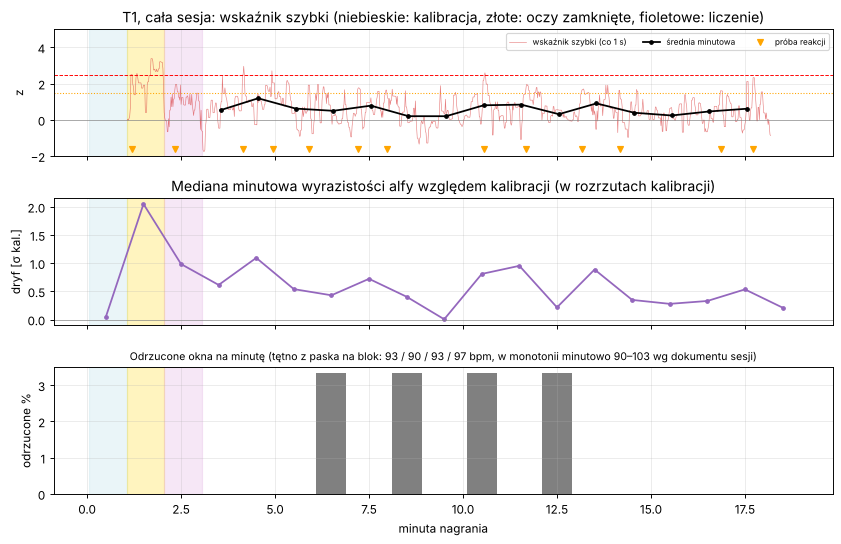

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
ax = axes[0]
ax.plot(t1.t / 60, t1.fast, lw=0.5, color="tab:red", alpha=0.6, label="wskaźnik szybki (co 1 s)")
ax.plot((mono.onset + 60 * (MIN.index - 0.5)) / 60, MIN["wskaźnik szybki (średnia)"], "o-", color="k", ms=3, label="średnia minutowa")
ax.axhline(CFG.z_enter, color="r", ls="--", lw=0.8); ax.axhline(CFG.probe_z, color="orange", ls=":", lw=0.9)
ax.axhline(0, color="gray", lw=0.5)
pr = t1[t1.probe]
ax.plot(pr.t / 60, np.full(len(pr), -1.6), "v", color="orange", ms=5, label="próba reakcji")
for a in axes:
    for b in blocks:
        a.axvspan(b.onset / 60, b.end / 60, color={"eyes_open": "lightblue", "eyes_closed": "gold", "math": "plum"}.get(b.label, "none"), alpha=0.25)
ax.set_ylim(-2, 5); ax.set_ylabel("z"); ax.legend(fontsize=7, loc="upper right", ncol=3)
ax.set_title("T1, cała sesja: wskaźnik szybki (niebieskie: kalibracja, złote: oczy zamknięte, fioletowe: liczenie)")
axes[1].plot(drift.index + 0.5, drift.values, "o-", color="tab:purple", ms=3)
axes[1].axhline(0, color="gray", lw=0.5); axes[1].set_ylabel("dryf [σ kal.]")
axes[1].set_title("Mediana minutowa wyrazistości alfy względem kalibracji (w rozrzutach kalibracji)")
rej = t1[t1.t <= mono.end].groupby((t1.t // 60).astype(int)).bad.mean() * 100
axes[2].bar(rej.index + 0.5, rej.values, width=0.8, color="gray")
axes[2].set_ylabel("odrzucone %"); axes[2].set_xlabel("minuta nagrania")
axes[2].set_title(f"Odrzucone okna na minutę (tętno z paska na blok: {HR_T1['eyes_open']} / {HR_T1['eyes_closed']} / "
                  f"{HR_T1['math']} / {HR_T1['monotony']} bpm, w monotonii minutowo 90–103 wg dokumentu sesji)", fontsize=9)
plt.tight_layout(); plt.show()

**Wynik:**

- **Brak trendu.** Średnia minutowa wskaźnika waha się od 0,20 do 1,19 (maksimum w 2. minucie). Trend (Theil–Sen na medianach minut):
  −0,18 z na 10 min, 95% CI [−0,72; +0,36]. Pierwsze 2 min 0,86, ostatnie 2 min 0,54 (dokument sesji podaje 0,88 → 0,54;
  0,88 to średnia okien z pierwszych 120 s, tu średnia dwóch średnich minutowych).
- **Odrzucenia są stałe i rzadkie:** 0–3,3% na minutę, po jednym oknie w 4 z 15 minut.
- **Próby rozkładają się równo:** 5, 2 i 4 w kolejnych pięciominutówkach. To nie jest reakcja na narastające zmęczenie, tylko
  stały „szum” reguły.
- **Wskaźnik raz po raz dotyka progu alarmu:** 3 pojedyncze okna powyżej 2,5 (najwyżej 2,96), każde trwało 1 s, a alarm wymaga 3 s.
  Od alarmu chroni więc wymóg czasu trwania, a nie zapas amplitudy.
- **Linia bazowa jest stabilna, ale przesunięta.** W minutach monotonii surowa wyrazistość alfy odchodzi od kalibracji o 0,00–1,09
  rozrzutu, mediana 0,43. Monotonia z otwartymi oczami ma więc stale nieco wyższą alfę niż fiksacja w kalibracji; przez 18 minut
  ta różnica nie rośnie.

## 4. Oddech i wskaźnik „stres” z zegarka

Plik `.fit` z zegarka Wojtka (oddech i wskaźnik „stres” Garmina co sekundę) zostaje na jego komputerze i **nie był dostępny** dla tej analizy,
więc nie podajemy z niego żadnych liczb. Gdyby był, wyrównalibyśmy oba przebiegi do minut monotonii (z dokładnością ok. 3 s, jak tętno)
i sprawdzili, czy mają trend albo czy idą w parze ze wskaźnikiem alfy minuta po minucie; to tylko uzupełnienie opisu stanu, nie miara zmęczenia.

## 5. Wykres na slajd

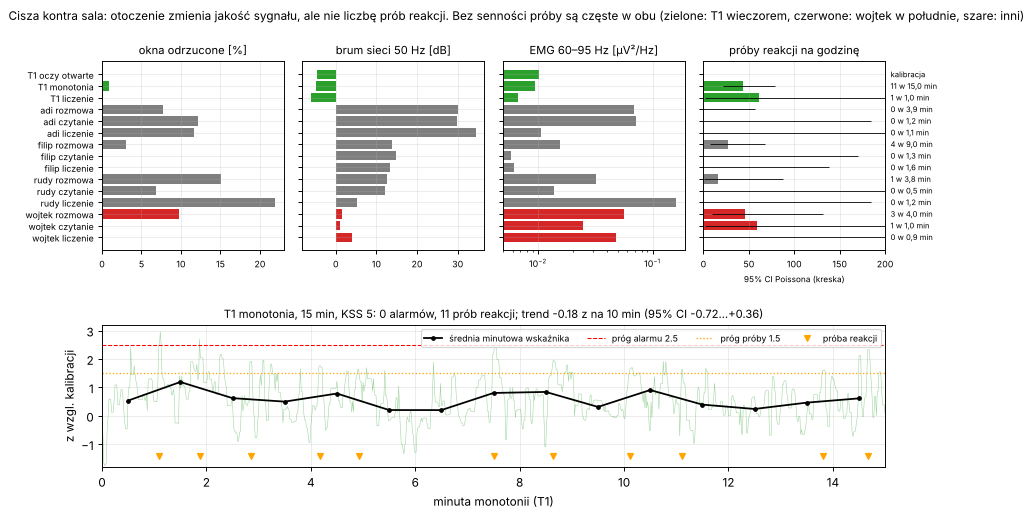

Zapisano docs/img/t1-kontrola-negatywna.png: 120 kB


In [10]:
IMG = REPO / "docs" / "img" / "t1-kontrola-negatywna.png"
plot = TAB.copy()
plot["etykieta"] = np.where(plot.rec == "wojtek-t1", "T1 " + plot.blok.str.replace(" (kalibracja)", ""),
                            plot.osoba + " " + plot.blok)
plot = plot[~((plot.rec == "wojtek-t1") & (plot.label == "eyes_closed"))]       # not an open-eyes condition
colors = np.where(plot.rec == "wojtek-t1", "tab:green", np.where(plot.osoba == "wojtek", "tab:red", "tab:gray"))
ypos = np.arange(len(plot))[::-1]

fig = plt.figure(figsize=(13, 6.2), dpi=85)
gs = fig.add_gridspec(2, 5, height_ratios=[1, 0.75], width_ratios=[1, 1, 1, 1, 0.3], hspace=0.45, wspace=0.12)
panels = [("odrzucone %", "okna odrzucone [%]", False), ("sieć 50 Hz [dB]", "brum sieci 50 Hz [dB]", False),
          ("EMG 60–95 Hz [µV²/Hz]", "EMG 60–95 Hz [µV²/Hz]", True), ("próby/h", "próby reakcji na godzinę", False)]
for i, (col, title, logx) in enumerate(panels):
    ax = fig.add_subplot(gs[0, i])
    ax.barh(ypos, plot[col].fillna(0), color=colors)
    if col == "próby/h":
        ci = np.array([poisson_ci(r["próby"], r["min po kal."] / 60) if pd.notna(r[col]) else (np.nan, np.nan)
                       for _, r in plot.iterrows()])
        ax.hlines(ypos, ci[:, 0], ci[:, 1], color="k", lw=0.7)
        for y, (_, r) in zip(ypos, plot.iterrows()):
            txt = "kalibracja" if pd.isna(r[col]) else f"{r['próby']} w {r['min po kal.']:.1f} min".replace(".", ",")
            ax.text(1.03, y, txt, va="center", fontsize=6.5, transform=ax.get_yaxis_transform())
        ax.set_xlim(0, 200); ax.set_xlabel("95% CI Poissona (kreska)", fontsize=7)
    if logx:
        ax.set_xscale("log")
    ax.set_yticks(ypos); ax.set_yticklabels(plot.etykieta if i == 0 else [], fontsize=7.5)
    ax.set_title(title, fontsize=9.5); ax.tick_params(axis="x", labelsize=7.5)
ax = fig.add_subplot(gs[1, :4])
x = (mono.onset + 60 * (MIN.index - 0.5)) / 60 - mono.onset / 60
ax.plot(t1.t / 60 - mono.onset / 60, t1.fast, lw=0.4, color="tab:green", alpha=0.5)
ax.plot(x, MIN["wskaźnik szybki (średnia)"], "o-", color="k", ms=3, label="średnia minutowa wskaźnika")
ax.axhline(CFG.z_enter, color="r", ls="--", lw=0.9, label=f"próg alarmu {CFG.z_enter}")
ax.axhline(CFG.probe_z, color="orange", ls=":", lw=1.1, label=f"próg próby {CFG.probe_z}")
ax.plot(pr.t / 60 - mono.onset / 60, np.full(len(pr), -1.4), "v", color="orange", ms=5, label="próba reakcji")
ax.set_xlim(0, mono.duration / 60); ax.set_ylim(-1.8, 3.2)
ax.set_xlabel("minuta monotonii (T1)"); ax.set_ylabel("z wzgl. kalibracji")
ax.legend(fontsize=7.5, ncol=4, loc="upper right")
n_alarm = int(MIN.alarmy.sum()); n_probe = int(MIN.próby.sum())
ax.set_title(f"T1 monotonia, 15 min, KSS 5: {n_alarm} alarmów, {n_probe} prób reakcji; trend {10 * slope:+.2f} z na 10 min "
             f"(95% CI {10 * lo:+.2f}…{10 * hi:+.2f})", fontsize=9.5)
fig.suptitle("Cisza kontra sala: otoczenie zmienia jakość sygnału, ale nie liczbę prób reakcji. Bez senności próby są częste w obu "
             "(zielone: T1 wieczorem, czerwone: wojtek w południe, szare: inni)", fontsize=10)
fig.savefig(IMG, dpi=85, bbox_inches="tight")
plt.show()
print(f"Zapisano docs/img/{IMG.name}: {IMG.stat().st_size / 1024:.0f} kB")

## 6. Co z tego wynika dla produktu

1. **Próba reakcji (issue #14): obecna reguła wywołuje próby bez senności i robi to w każdych warunkach.** 44 na godzinę w ciszy
   (11 w 15 min, KSS 5), 18 na godzinę w sali (9 w 29,5 min), 41 na godzinę u Wojtka w sali. Lepszy sygnał tego nie naprawi,
   bo w najczystszym nagraniu prób jest najwięcej. Próba powinna iść z harmonogramu albo po zdarzeniu (np. co 20 min, czyli 3 na godzinę), nie z podprogowej alfy.
2. **Próg alarmu 2,5 przez 3 s trzyma fałszywe alarmy nisko niezależnie od sali:** 0 w 15 min w ciszy, 1 w 29,5 min w sali
   (2 na godzinę, CI 0–11). Ale w T1 wskaźnik trzy razy dotknął progu (do 2,96) na 1 s, więc **nie skracać `lapse_min_s` poniżej 3 s**:
   to on, a nie zapas amplitudy, daje zero alarmów.
3. **Łączenie zdarzeń (issue #11):** w 3 z 5 bloków zamkniętych oczu (T1, adi, wojtek w południe) produkt zgłosił 2 alarmy zamiast
   jednego. Zdarzenia rozdzielone krótką przerwą trzeba scalać, inaczej jedno zamknięcie oczu liczy się jako dwa spadki.
4. **Kalibracja (issue #18): zawsze od nowa po założeniu czepka, nigdy z innej sesji.** Kalibracja Wojtka z południa przyłożona
   do wieczornej monotonii daje 17 alarmów zamiast 0; środki kalibracji różnią się o 0,48 rozrzutu. W obrębie jednej sesji linia bazowa
   była stabilna przez 18 min (dryf 0,00–1,09 rozrzutu, bez trendu), więc ponowna kalibracja w trakcie 15–20 min nie jest potrzebna.
5. **Kalibracja powinna wyglądać jak monitorowana czynność.** Monotonia siedziała stale ok. 0,4 rozrzutu (mediana dryfu 0,43; mediana z 0,54)
   nad kalibracją z fiksacji wzroku; to przesunięcie, a nie zmęczenie, daje 11,2% okien nad progiem próby.
6. **Demo w sali (issue #12): jakość sygnału trzeba pokazać, bo zależy od sesji.** Brum od −4,8 dB (T1) do 34,5 dB (adi), odrzucone
   okna od 0,9% do 21,9%. Przed demem sprawdzić brum i kafelek jakości; w trakcie demo nie mówić z czepkiem, bo rozmowa podnosi EMG
   3,2–5,9 razy i odrzucenia o 6–9 pp.
7. **Na demo z obecną regułą trzeba zapowiedzieć próby:** przy 18–44 próbach na godzinę bez senności widz zobaczy próbę mniej więcej co 1,5–3,5 min.
   Albo przełączyć demo na próby z harmonogramu, albo powiedzieć wprost, że to częstość kontrolna, a nie wykrycie zmęczenia.

## Wnioski

**W 15 minutach monotonii przy KSS 5 było 0 fałszywych alarmów i 11 prób reakcji (44 na godzinę). W hałaśliwej sali
(29,5 min bloków z otwartymi oczami, 4 osoby) było 1 fałszywy alarm i 9 prób (18 na godzinę).** Otoczenie mocno zmienia jakość
sygnału, ale nie zwiększa liczby alarmów ani prób:

| | T1 monotonia (cicho) | Południe, sala (bloki z otwartymi oczami) |
|---|---|---|
| okna odrzucone | 0,9% | 0–21,9% (rozmowa 3,0–15,1%) |
| brum sieci 50 Hz | −4,8 dB | 1,1–34,5 dB, zależnie od sesji |
| EMG 60–95 Hz | 0,009 µV²/Hz | 0,006–0,161 µV²/Hz (rozmowa 0,016–0,069) |
| mediana wskaźnika z (p90) | 0,54 (1,54) | rozmowa od −0,28 do 0,19 (0,65–1,56) |
| fałszywe alarmy na godzinę | 0 (CI 0–15) | 2 (CI 0–11) |
| próby reakcji na godzinę | 44 (CI 22–79) | 18 (CI 8–35) |

1. **Sala pogarsza sygnał, nie wskaźnik.** Względem T1 brum jest wyższy o 6–19 dB, EMG 1,5–5,9 razy, okien odrzuconych o 6–9 pp więcej (poza krótkimi blokami czytania i liczenia Wojtka, bez odrzuceń),
   a mediana wskaźnika w sali jest niższa (o 0,10–0,69). Odrzucanie okien, notch i względna miara alfy wystarczają, żeby szum
   sali nie zamieniał się w alarmy.
2. **Wynik T1 „0 alarmów, 11 prób” nie jest zawyżony ani zaniżony przez ciszę.** Zero alarmów zgadza się z salą (1 w 29,5 min).
   Próby w ciszy są nawet częstsze, bo monotonia leży ok. 0,4 rozrzutu nad kalibracją z fiksacji wzroku. Częste próby to cecha
   reguły (próg 1,5), nie otoczenia.
3. **Najsilniej wskaźnikiem rusza kalibracja z innej sesji:** u Wojtka 0 → 17 alarmów w tej samej monotonii. Kalibrować przy każdym założeniu czepka.
4. **W 15 minutach monotonii nie ma trendu:** −0,18 z na 10 min (95% CI −0,72 do +0,36), odrzucenia 0–3,3% na minutę, dryf linii bazowej
   do 1,09 rozrzutu przez 18 min, próby rozłożone równo (5, 2, 4 na pięciominutówkę). Tętno z paska 93 / 90 / 93 / 97 bpm na blok
   (dane z dokumentu sesji).
5. Wskaźnik w T1 dotknął progu alarmu (najwyżej 2,96) trzy razy, każdorazowo na 1 s; alarmu nie było dzięki wymogowi 3 s.
   Dokument sesji mówi, że wskaźnik „ani razu nie zbliżył się do progu alarmu”; to prawda dla średnich minutowych (maks. 1,19),
   ale nie dla wartości sekundowych.

Co wolno powiedzieć: „W 15 minutach monotonii przy KSS 5 system nie zgłosił ani jednego fałszywego alarmu; w hałaśliwej sali
1 w ok. 30 minutach”. Nie wolno: że ta sesja pokazała wykrywanie zmęczenia i czujności w sensie senności. Senności w niej nie było,
więc to kontrola negatywna, nie test czułości.

**Ograniczenia:**

- T1 to jedna osoba i jedna sesja; porównanie „cisza kontra sala” dla tej samej osoby to jedna para sesji Wojtka.
- Warunki różnią się naraz salą, czynnością (monotonia, rozmowa, czytanie, liczenie), porą dnia, założeniem czepka i kalibracją
  (fiksacja wzroku w T1, rozmowa w południe). Tabela pokazuje wielkość różnic, nie ich przyczynę.
- Bloki czytania i liczenia z południa trwają 0,5–1,6 min; ich częstości zdarzeń mają przedziały ufności do kilkuset na godzinę,
  a bootstrap blokowy na tak krótkich blokach zaniża niepewność.
- Ruch z akcelerometru to zgrubna miara (sygnał o niskiej rozdzielczości), podana tylko względnie.
- Tętno pochodzi wyłącznie z dokumentu sesji; oddechu i wskaźnika „stres” z zegarka nie analizowaliśmy (plik niedostępny).